# EDA — base da TBCA sem receitas e mapa SOM retreinado

O que este notebook olha, em ordem:

1. **A limpeza** — o que saiu da TBCA (receitas) e o que ficou, por classe e por motivo.
2. **A base que entra no mapa** — grupos, nutrientes normalizados (Min-Max), imputação, correlações e quem define o máximo de cada nutriente.
3. **As classificações** — NOVA, Nutri-Score, alérgenos e dietas por grupo do prato.
4. **O mapa SOM 10×10** — ocupação, U-matrix, grupo dominante por gaveta, planos de componentes, alimentos mal encaixados e onde ficam os ingredientes do app.
5. **Qualidade das substituições** — vizinhos do SOM × kNN (sklearn), por grupo, e antes × depois da limpeza.

Dados: `kb/som/tbca_som.csv`, `kb/som/som_tbca.npz`, `kb/som/tbca_receitas_removidas.csv` e `fontes/TBCA_dados_modelo.xlsx`.
Rode a partir da pasta do repositório ou de `notebooks/`.

In [1]:
import sys, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.neighbors import NearestNeighbors

RAIZ = Path.cwd() if (Path.cwd() / "kb").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from agents.substituidor import Substituidor

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

s = Substituidor()                      # carrega a tabela, o mapa e calcula a gaveta (BMU) de cada alimento
d = s.d.copy()
X, W, L = s.X, s.pesos, s.lado
d["lin"], d["col"] = s.gaveta[:, 0], s.gaveta[:, 1]
d["neuronio"] = d.lin * L + d.col
nutrientes = [c[2:] for c in d.columns if c.startswith("n_")]

removidas = pd.read_csv(RAIZ / "kb/som/tbca_receitas_removidas.csv")
tbca = pd.read_excel(RAIZ / "fontes/TBCA_dados_modelo.xlsx", sheet_name="nutrientes_limpos")

GRUPOS = d.grupo.value_counts().index.tolist()
CORES = ["#2a6fdb", "#e8833a", "#3aa76d", "#c94f7c", "#8e6cc9", "#7a5c3e", "#d4b106", "#4fb3bf",
         "#5d6d7e", "#e15759", "#9c9c9c"]
COR = dict(zip(GRUPOS, CORES))
print(f"{len(d)} alimentos no mapa | {len(removidas)} receitas fora | TBCA original: {len(tbca)}")
print(f"mapa {L}x{L}, {len(nutrientes)} nutrientes de entrada | erro de quantização {s.qe:.3f} | erro topográfico {s.te:.3f}")

2556 alimentos no mapa | 3112 receitas fora | TBCA original: 5668
mapa 10x10, 37 nutrientes de entrada | erro de quantização 0.205 | erro topográfico 0.022


## 1. A limpeza: o que saiu e o que ficou

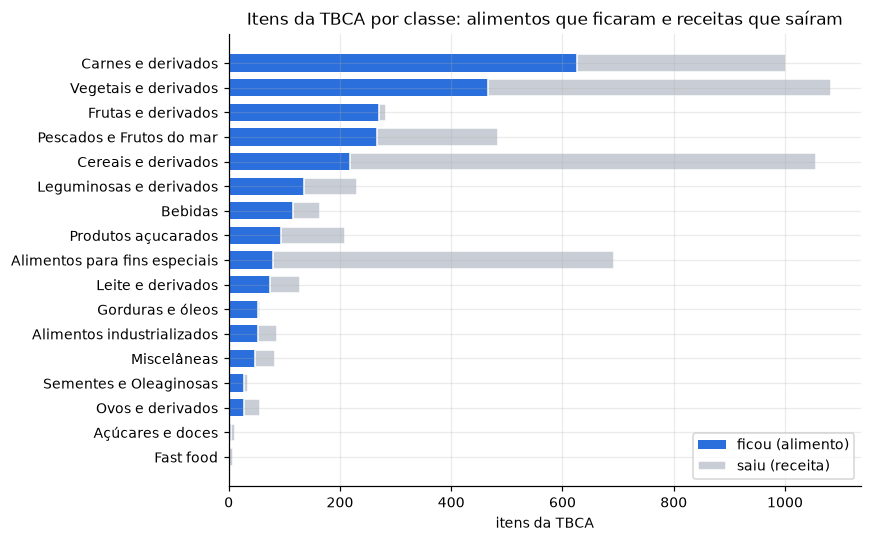

,ficou,saiu (receita),% que saiu
classe,,,
Fast food,0,7,100.0
Alimentos para fins especiais,79,614,88.6
Cereais e derivados,218,838,79.4
Açúcares e doces,4,7,63.6
Vegetais e derivados,467,616,56.9
Produtos açucarados,94,115,55.0
Ovos e derivados,28,28,50.0
Pescados e Frutos do mar,266,218,45.0
Miscelâneas,47,37,44.0


In [2]:
por_classe = pd.DataFrame({"ficou": d.classe.value_counts(), "saiu (receita)": removidas.classe.value_counts()}).fillna(0).astype(int)
por_classe["% que saiu"] = (100 * por_classe["saiu (receita)"] / por_classe.sum(axis=1)).round(1)
por_classe = por_classe.sort_values("ficou")

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(por_classe))
ax.barh(y, por_classe["ficou"], color="#2a6fdb", label="ficou (alimento)", height=0.7)
ax.barh(y, por_classe["saiu (receita)"], left=por_classe["ficou"], color="#c9ced6", label="saiu (receita)", height=0.7,
        edgecolor="white", linewidth=1)
ax.set_yticks(y, por_classe.index); ax.set_xlabel("itens da TBCA"); ax.legend(loc="lower right")
ax.set_title("Itens da TBCA por classe: alimentos que ficaram e receitas que saíram")
plt.tight_layout(); plt.show()
por_classe.sort_values("% que saiu", ascending=False)

In [3]:
print(removidas.motivo.value_counts().to_string(), "\n")
for m, g in removidas.groupby("motivo"):
    print(f"--- {m}: exemplos")
    print(g.descricao.sample(min(4, len(g)), random_state=0).str.slice(0, 110).to_string(index=False), "\n")

motivo
lista de ingredientes           1314
nome de prato                   1272
alimento misturado com outro     516
prato 'com'                        9
fast food                          1 

--- alimento misturado com outro: exemplos
Carne, boi, maminha, s/ gordura, assada, recheado - cebola, pimentão, tomate, linguiça ...
Carne, boi, acém moída, cozida, c/ vegetais - cenoura, chuchu, vagem, c/ óleo, cebola e...
Carne, boi, peito, s/ gordura, grelhada, c/ molho branco (farinha de trigo, manteiga e ...
Carne, boi, miolo de alcatra (baby beef), grelhada/assada, s/ óleo, c/ molho roti (cald... 

--- fast food: exemplos
Batata frita, McDonald´s 

--- lista de ingredientes: exemplos
Pirão de leite, s/ sal, (leite, farinha de mandioca (aipim, macaxeira), manteiga, cebol...
Rondele, ricota e espinafre, c/ molho de tomate, caseiro, c/ sal, (massa com farinha de...
Gelatina colorida, c/ creme, (gelatina diversos sabores, gelatina sem sabor, água, crem...
Sopa, inhame, s/ sal, (inhame, c/ cal

## 2. A base que entra no mapa

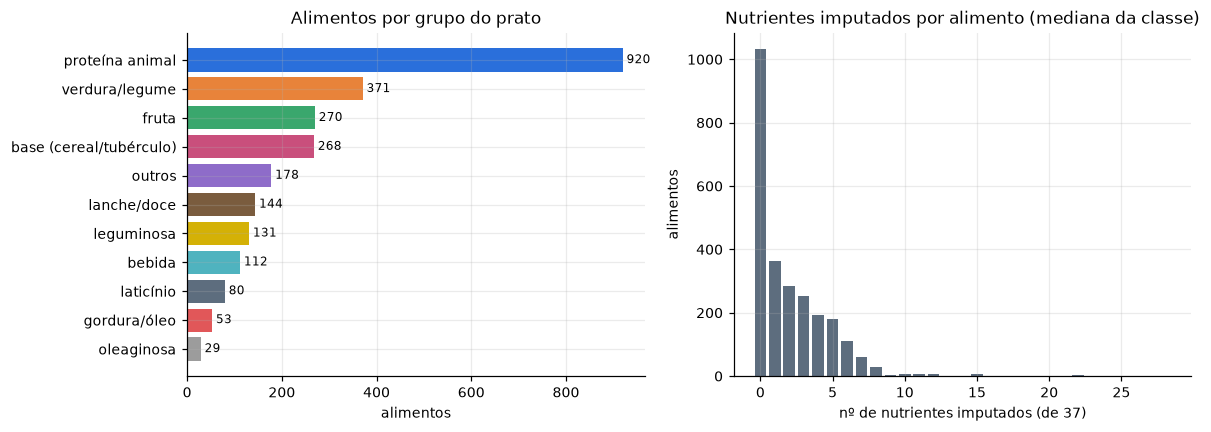

40% dos alimentos sem nenhum valor imputado; 42 com 10 ou mais (menos confiáveis)

nutrientes mais vazios na TBCA (antes da imputação):
selenio_mcg        32.1 %
gord_trans_g       25.2 %
vit_a_re_mcg       21.5 %
acucar_adicao_g    21.5 %
sal_adicao_g       21.2 %
vit_e_mg           13.2 %
vit_d_mcg          13.1 %
folato_mcg          8.9 %


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
vc = d.grupo.value_counts()
axs[0].barh(vc.index[::-1], vc.values[::-1], color=[COR[g] for g in vc.index[::-1]])
axs[0].set_title("Alimentos por grupo do prato"); axs[0].set_xlabel("alimentos")
for i, v in enumerate(vc.values[::-1]):
    axs[0].text(v + 8, i, str(v), va="center", fontsize=8)
f = d.faltantes_imputados.value_counts().sort_index()
axs[1].bar(f.index, f.values, color="#5d6d7e")
axs[1].set_title("Nutrientes imputados por alimento (mediana da classe)"); axs[1].set_xlabel("nº de nutrientes imputados (de 37)")
axs[1].set_ylabel("alimentos")
plt.tight_layout(); plt.show()
print(f"{(d.faltantes_imputados == 0).mean():.0%} dos alimentos sem nenhum valor imputado; "
      f"{(d.faltantes_imputados >= 10).sum()} com 10 ou mais (menos confiáveis)")
falt = tbca[tbca.codigo.isin(d.codigo)][nutrientes].isna().mean().sort_values(ascending=False)
print("\nnutrientes mais vazios na TBCA (antes da imputação):"); print((100 * falt.head(8)).round(1).astype(str).add(" %").to_string())

### Distribuição dos nutrientes normalizados

Com Min-Max, cada nutriente vai de 0 a 1, mas **um único alimento extremo define o 1**. Se a maioria dos alimentos fica
espremida perto de 0, aquele nutriente pesa pouco na distância — e o mapa quase não o enxerga.

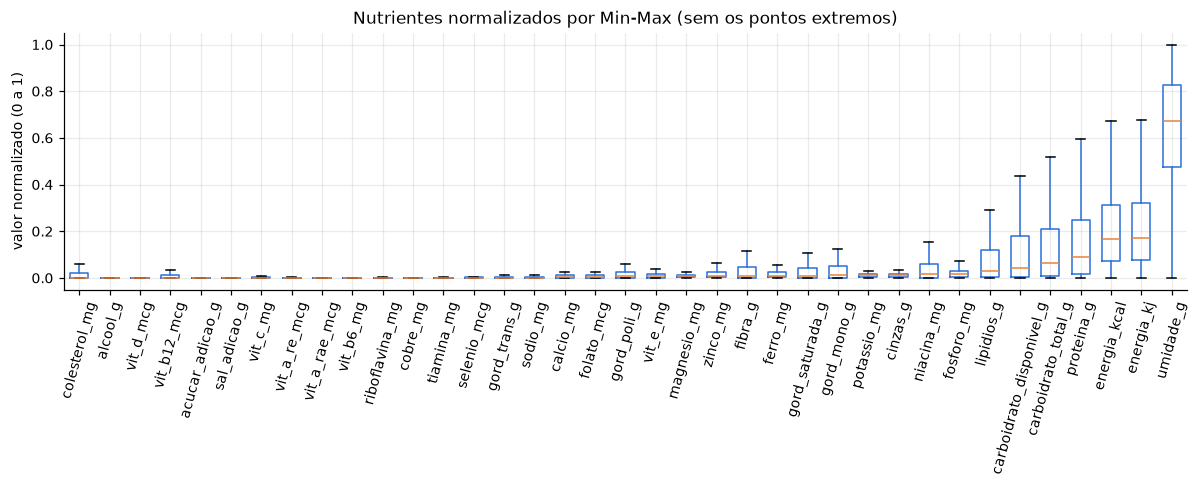

,mediana,"% abaixo de 0,05",desvio padrão,alimento que define o máximo (= 1)
tiamina_mg,0.001,99.9,0.020,"Mirtilo, desidratado, Vaccinium myrtillus L."
riboflavina_mg,0.000,99.9,0.025,"Mirtilo, desidratado, Vaccinium myrtillus L."
selenio_mcg,0.001,99.9,0.025,"Castanha do Brasil, crua, Bertholletia excelsa H.B.K."
vit_d_mcg,0.000,99.8,0.020,"Óleo, cação, fígado (média de diferentes amostras)"
vit_b6_mg,0.000,99.8,0.020,"Mirtilo, desidratado, Vaccinium myrtillus L."
cobre_mg,0.000,99.4,0.022,"Fécula de batata, crua"
sal_adicao_g,0.000,99.4,0.047,"Sal rosa, Himalaia"
alcool_g,0.000,99.1,0.056,"Bebida alcoólica, destilada (gim, rum, vodka, whisky) (teor"
vit_a_rae_mcg,0.000,98.9,0.035,"Óleo, cação, fígado (média de diferentes amostras)"
sodio_mg,0.002,98.7,0.051,Flor de sal


In [5]:
N = d[["n_" + c for c in nutrientes]]
ordem = N.median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([N[c] for c in ordem], tick_labels=[c[2:] for c in ordem], showfliers=False, widths=0.6,
           medianprops={"color": "#e8833a"}, boxprops={"color": "#2a6fdb"}, whiskerprops={"color": "#2a6fdb"})
ax.tick_params(axis="x", rotation=75); ax.set_ylabel("valor normalizado (0 a 1)")
ax.set_title("Nutrientes normalizados por Min-Max (sem os pontos extremos)")
plt.tight_layout(); plt.show()

resumo = pd.DataFrame({
    "mediana": N.median().round(3),
    "% abaixo de 0,05": (100 * (N < 0.05).mean()).round(1),
    "desvio padrão": N.std().round(3)})
resumo.index = [c[2:] for c in resumo.index]
quem = {c: d.descricao[N["n_" + c].idxmax()][:60] for c in nutrientes}
resumo["alimento que define o máximo (= 1)"] = pd.Series(quem)
resumo.sort_values("% abaixo de 0,05", ascending=False)

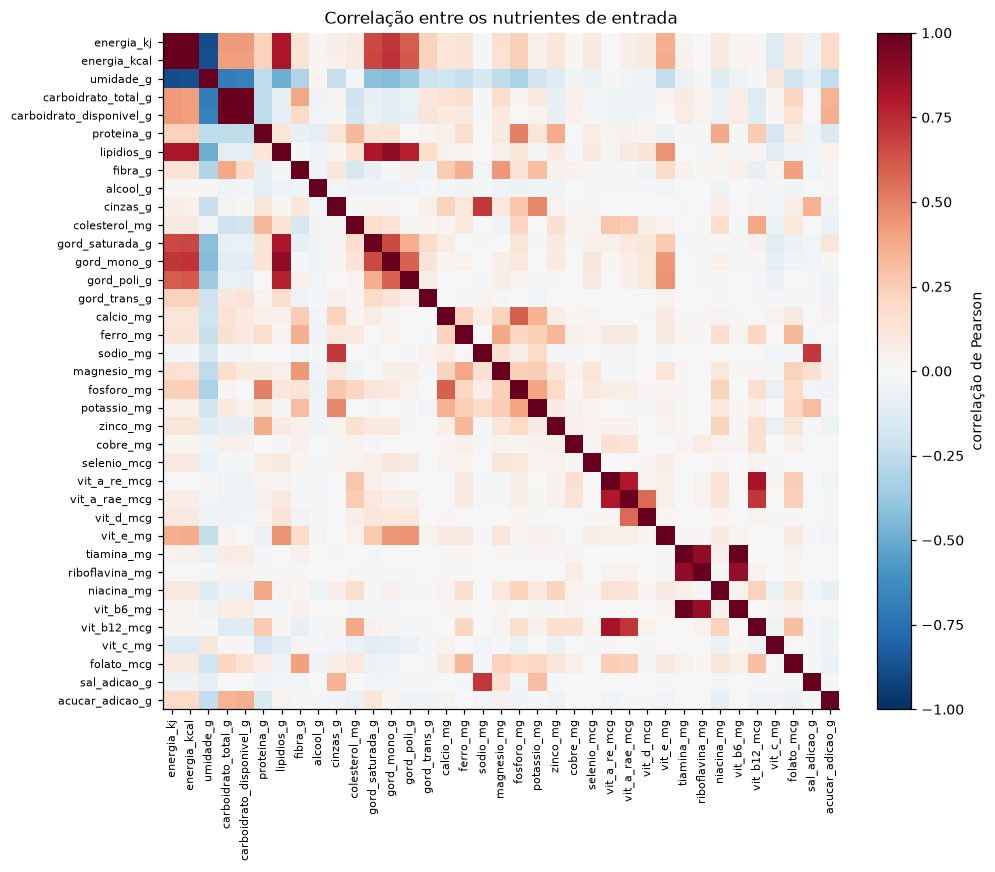

pares mais correlacionados (informação repetida na entrada do mapa):
energia_kj           energia_kcal                0.999
tiamina_mg           vit_b6_mg                   0.990
carboidrato_total_g  carboidrato_disponivel_g    0.979
lipidios_g           gord_mono_g                 0.890
tiamina_mg           riboflavina_mg              0.890
energia_kj           umidade_g                  -0.889
energia_kcal         umidade_g                  -0.882
riboflavina_mg       vit_b6_mg                   0.879
vit_a_re_mcg         vit_b12_mcg                 0.821
energia_kcal         lipidios_g                  0.815


In [6]:
C = N.corr(); C.index = C.columns = nutrientes
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C)), C.columns, rotation=90, fontsize=7); ax.set_yticks(range(len(C)), C.index, fontsize=7)
ax.grid(False); plt.colorbar(im, fraction=0.046, label="correlação de Pearson")
ax.set_title("Correlação entre os nutrientes de entrada")
plt.tight_layout(); plt.show()
pares = C.where(np.triu(np.ones(C.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print("pares mais correlacionados (informação repetida na entrada do mapa):")
print(pares.head(10).round(3).to_string())

## 3. Classificações por grupo do prato

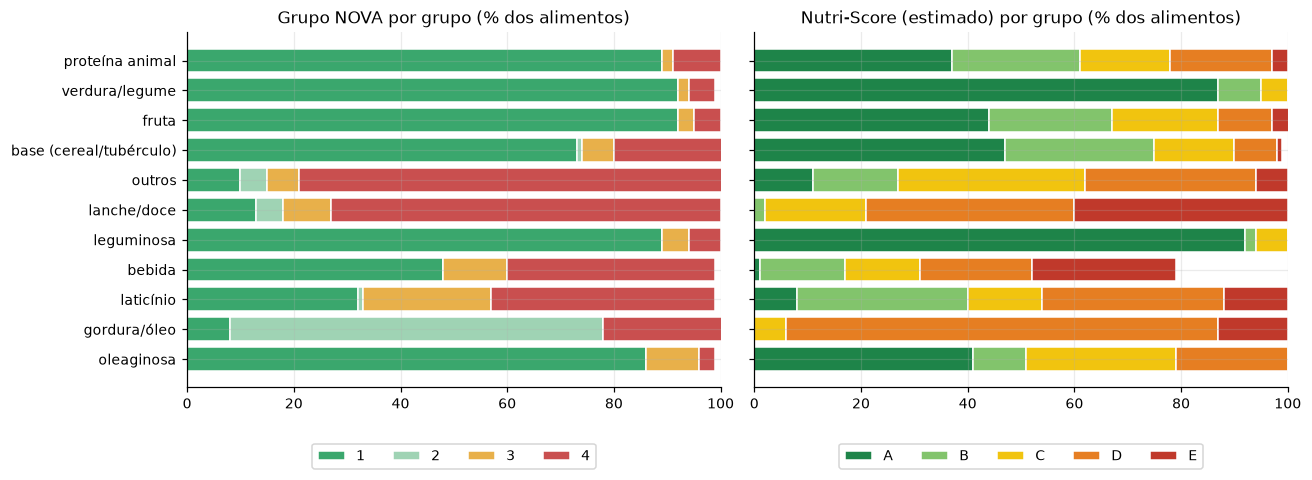

In [7]:
def pct(col):
    return (100 * pd.crosstab(d.grupo, d[col], normalize="index")).round(0).loc[GRUPOS]

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, col, cores, titulo in [(axs[0], "nova", ["#3aa76d", "#9fd3b4", "#e8b04a", "#c94f4f"], "Grupo NOVA"),
                               (axs[1], "nutriscore", ["#1e8449", "#82c46c", "#f1c40f", "#e67e22", "#c0392b"], "Nutri-Score (estimado)")]:
    t = pct(col)
    t = t[[c for c in t.columns if str(c) != ""]]
    esq = np.zeros(len(t))
    for c, cor in zip(t.columns, cores):
        ax.barh(t.index, t[c], left=esq, color=cor, label=str(c), edgecolor="white", linewidth=1)
        esq += t[c].values
    ax.set_title(f"{titulo} por grupo (% dos alimentos)"); ax.set_xlim(0, 100); ax.legend(ncol=5, loc="lower center",
                                                                                         bbox_to_anchor=(0.5, -0.25))
axs[0].invert_yaxis()
plt.tight_layout(); plt.show()

In [8]:
al = [c for c in d.columns if c.startswith("alergeno_")]
di = [c for c in d.columns if c.startswith("dieta_")]
t = d.groupby("grupo")[al + di].mean().mul(100).round(0).loc[GRUPOS]
t.columns = [c.replace("alergeno_", "alérgeno: ").replace("dieta_", "dieta: ") for c in t.columns]
print("% dos alimentos de cada grupo com o alérgeno detectado / dentro da dieta (pelo nome):")
t.astype(int)

% dos alimentos de cada grupo com o alérgeno detectado / dentro da dieta (pelo nome):


,alérgeno: gluten,alérgeno: leite,alérgeno: ovos,alérgeno: peixes,alérgeno: crustaceos,alérgeno: amendoim,alérgeno: soja,alérgeno: castanhas_nozes,dieta: vegetariano,dieta: vegano,dieta: sem_gluten,dieta: sem_lactose
grupo,,,,,,,,,,,,
proteína animal,7,3,9,25,2,0,0,0,3,0,93,97
verdura/legume,4,5,3,0,0,0,1,0,99,91,96,95
fruta,2,7,1,0,0,0,0,3,100,93,98,93
base (cereal/tubérculo),35,13,4,0,1,0,0,1,94,80,65,87
outros,11,14,1,1,0,1,3,0,70,56,89,86
lanche/doce,26,19,3,1,0,1,0,5,94,71,74,81
leguminosa,2,4,0,0,0,0,24,0,97,93,98,96
bebida,2,27,0,1,0,0,3,1,99,72,98,73
laticínio,0,92,0,0,0,0,4,2,100,8,100,8


## 4. O mapa SOM 10×10

Cada alimento cai na **gaveta** (neurônio) cujo vetor de pesos é o mais próximo dos seus 37 nutrientes.
- **Ocupação**: quantos alimentos em cada gaveta.
- **U-matrix**: distância média de uma gaveta às vizinhas — valores altos são "fronteiras" entre regiões do mapa.
- **Grupo dominante e pureza**: qual grupo do prato manda em cada gaveta e que fração da gaveta ele ocupa.

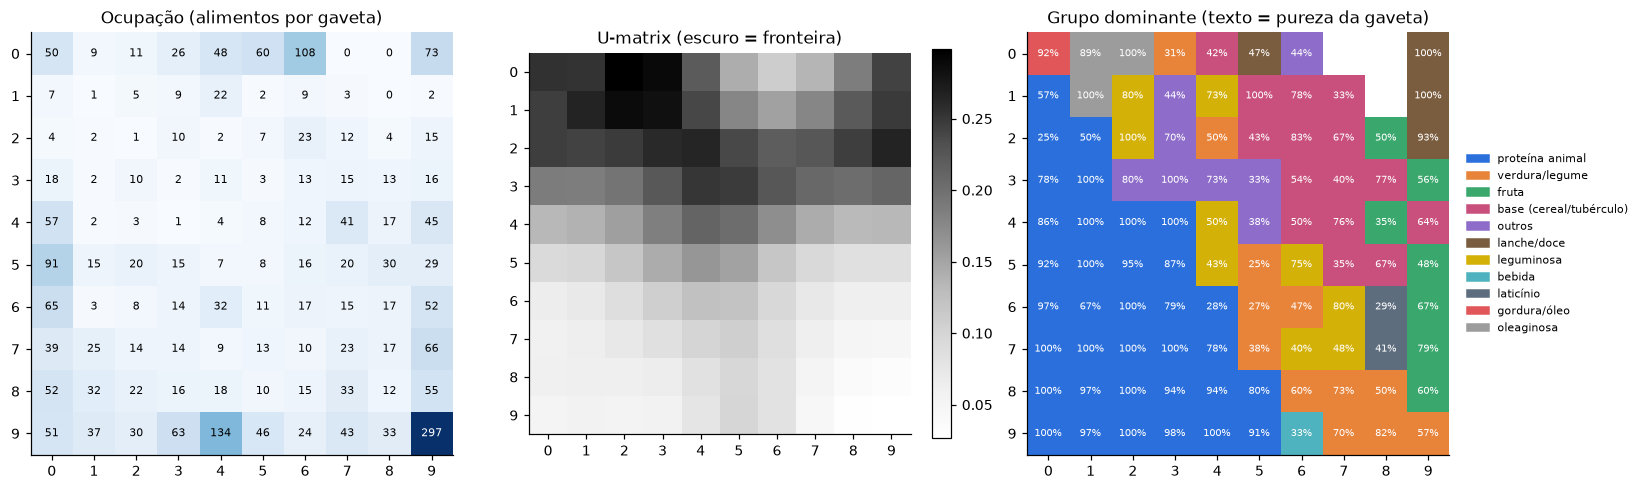

gavetas vazias: 3 de 100 | maior gaveta: 297 alimentos | mediana: 15
pureza média ponderada pelo tamanho da gaveta: 73.0%


In [9]:
ocup = np.bincount(d.neuronio, minlength=L * L).reshape(L, L)
U = np.zeros((L, L))
for i in range(L):
    for j in range(L):
        viz = [W[a, b] for a in range(max(0, i - 1), min(L, i + 2)) for b in range(max(0, j - 1), min(L, j + 2)) if (a, b) != (i, j)]
        U[i, j] = np.mean([np.linalg.norm(W[i, j] - v) for v in viz])

dom = np.full((L, L), -1); pureza = np.full((L, L), np.nan)
for (i, j), g in d.groupby(["lin", "col"]):
    vc = g.grupo.value_counts()
    dom[i, j] = GRUPOS.index(vc.index[0]); pureza[i, j] = vc.iloc[0] / len(g)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
im = axs[0].imshow(ocup, cmap="Blues"); axs[0].set_title("Ocupação (alimentos por gaveta)")
for (i, j), v in np.ndenumerate(ocup):
    axs[0].text(j, i, v, ha="center", va="center", fontsize=7, color="white" if v > ocup.max() * 0.6 else "black")
im2 = axs[1].imshow(U, cmap="Greys"); axs[1].set_title("U-matrix (escuro = fronteira)"); plt.colorbar(im2, ax=axs[1], fraction=0.046)
cmap = ListedColormap(CORES[:len(GRUPOS)])
axs[2].imshow(np.ma.masked_less(dom, 0), cmap=cmap, vmin=0, vmax=len(GRUPOS) - 1, alpha=1.0)
for (i, j), p in np.ndenumerate(pureza):
    if not np.isnan(p):
        axs[2].text(j, i, f"{p:.0%}", ha="center", va="center", fontsize=6.5, color="white")
axs[2].set_title("Grupo dominante (texto = pureza da gaveta)")
axs[2].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COR[g]) for g in GRUPOS], labels=GRUPOS, fontsize=7,
              loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
for ax in axs:
    ax.grid(False); ax.set_xticks(range(L)); ax.set_yticks(range(L))
plt.tight_layout(); plt.show()

vazias = int((ocup == 0).sum())
print(f"gavetas vazias: {vazias} de {L*L} | maior gaveta: {ocup.max()} alimentos | mediana: {int(np.median(ocup))}")
print(f"pureza média ponderada pelo tamanho da gaveta: {np.nansum(pureza * ocup) / ocup.sum():.1%}")

In [10]:
print("O que tem nas 6 gavetas mais cheias:")
for n in np.argsort(-ocup.ravel())[:6]:
    g = d[d.neuronio == n]
    print(f"\n[{n // L},{n % L}] {len(g)} alimentos — " + ", ".join(f"{k} {v}" for k, v in g.grupo.value_counts().head(3).items()))
    print("   " + " | ".join(g.descricao.sample(min(5, len(g)), random_state=1).str.slice(0, 45)))

O que tem nas 6 gavetas mais cheias:

[9,9] 297 alimentos — verdura/legume 169, fruta 51, bebida 48
   Palmito, Pupunha, conserva, drenado, Bactris  | Berinjela, refogada (c/ óleo, cebola e alho), | Chuchu, s/ casca, cozido, drenado, c/ óleo de | Bebida, chá, lata/garrafa, limão, Lipton | Abóbora, s/ casca, s/ sementes, crua, Curcubi

[9,4] 134 alimentos — proteína animal 134
   Peixe, água salgada, cação, posta, assado/gre | Carne, vitela, crua, Bos taurus | Carne, novilho, crua (média de 10 espécies),  | Peixe, água doce, Tilápia, filé s/ pele, grel | Peixe, água salgada, abadejo, filé, congelado

[0,6] 108 alimentos — outros 47, base (cereal/tubérculo) 39, lanche/doce 11
   Sagu, framboesa, mistura p/, Ducoco | Torrada, trigo, tradicional | Gelatina, maracujá, em pó, Ducoco | Gelatina, uva, em pó, Ducoco | Creme, de milho, em pó

[5,0] 91 alimentos — proteína animal 84, laticínio 7
   Carne, boi, fraldinha, c/ gordura, frita (c/  | Queijo, requeijao do norte (queijo de manteig | Car

### Planos de componentes: como cada nutriente se espalha pelo mapa

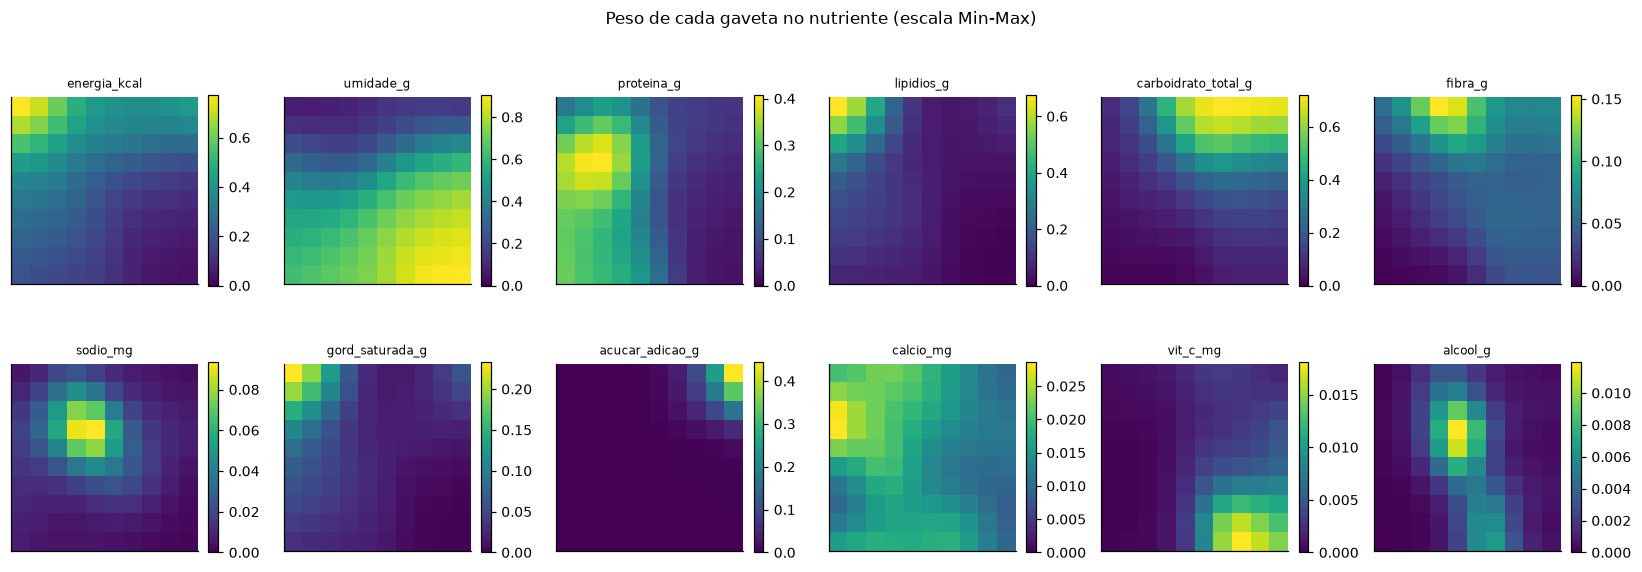

In [11]:
mostrar = ["energia_kcal", "umidade_g", "proteina_g", "lipidios_g", "carboidrato_total_g", "fibra_g",
           "sodio_mg", "gord_saturada_g", "acucar_adicao_g", "calcio_mg", "vit_c_mg", "alcool_g"]
idx = [nutrientes.index(c) for c in mostrar]
fig, axs = plt.subplots(2, 6, figsize=(15, 5.4))
for ax, c, k in zip(axs.ravel(), mostrar, idx):
    im = ax.imshow(W[:, :, k], cmap="viridis", vmin=0, vmax=max(W[:, :, k].max(), 1e-6))
    ax.set_title(c, fontsize=8); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Peso de cada gaveta no nutriente (escala Min-Max)", y=1.0)
plt.tight_layout(); plt.show()

### Alimentos mal encaixados (maior distância até a própria gaveta)

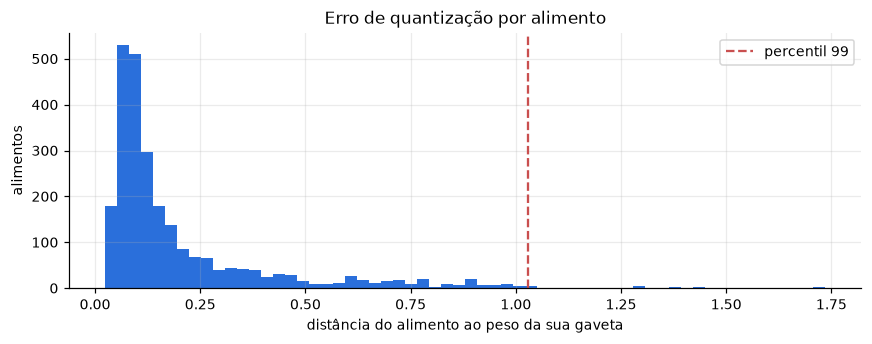

por grupo (média):
grupo
gordura/óleo               0.688
lanche/doce                0.593
oleaginosa                 0.413
outros                     0.358
bebida                     0.195
laticínio                  0.181
leguminosa                 0.178
proteína animal            0.157
base (cereal/tubérculo)    0.154
verdura/legume             0.141
fruta                      0.109


,descricao,grupo,lin,col,erro_quantizacao,faltantes_imputados
1194,"Mirtilo, desidratado, Vaccinium myrtillus L.",fruta,0,6,1.735,2
2272,"Sal, dietético",outros,3,4,1.724,28
1622,"Sal, refinado",outros,3,4,1.687,3
1373,Flor de sal,outros,3,4,1.577,6
2534,"Fermento, químico, em pó",outros,2,4,1.540,4
2010,"Óleo, cação, fígado (média de diferentes amostras)",gordura/óleo,0,0,1.532,4
1759,"Carne, boi, fígado, grelhada, s/ óleo, s/ sal, Bos taurus",proteína animal,9,0,1.500,1
2528,"Carne, boi, fígado, grelhada, c/ óleo e cebola, c/ sal",proteína animal,9,0,1.423,0
2043,"Carne, boi, fígado, grelhada, c/ óleo e cebola, s/ sal",proteína animal,9,0,1.423,0
2080,"Carne, boi, fígado, grelhada, s/ óleo, c/ sal, Bos taurus",proteína animal,8,0,1.390,0


In [12]:
d["erro_quantizacao"] = np.linalg.norm(X - W.reshape(-1, X.shape[1])[d.neuronio], axis=1)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(d.erro_quantizacao, bins=60, color="#2a6fdb")
ax.axvline(d.erro_quantizacao.quantile(0.99), color="#c94f4f", ls="--", label="percentil 99")
ax.set_xlabel("distância do alimento ao peso da sua gaveta"); ax.set_ylabel("alimentos"); ax.legend()
ax.set_title("Erro de quantização por alimento"); plt.tight_layout(); plt.show()
print("por grupo (média):"); print(d.groupby("grupo").erro_quantizacao.mean().sort_values(ascending=False).round(3).to_string())
d.nlargest(12, "erro_quantizacao")[["descricao", "grupo", "lin", "col", "erro_quantizacao", "faltantes_imputados"]].round(3)

### Onde ficam os ingredientes do app

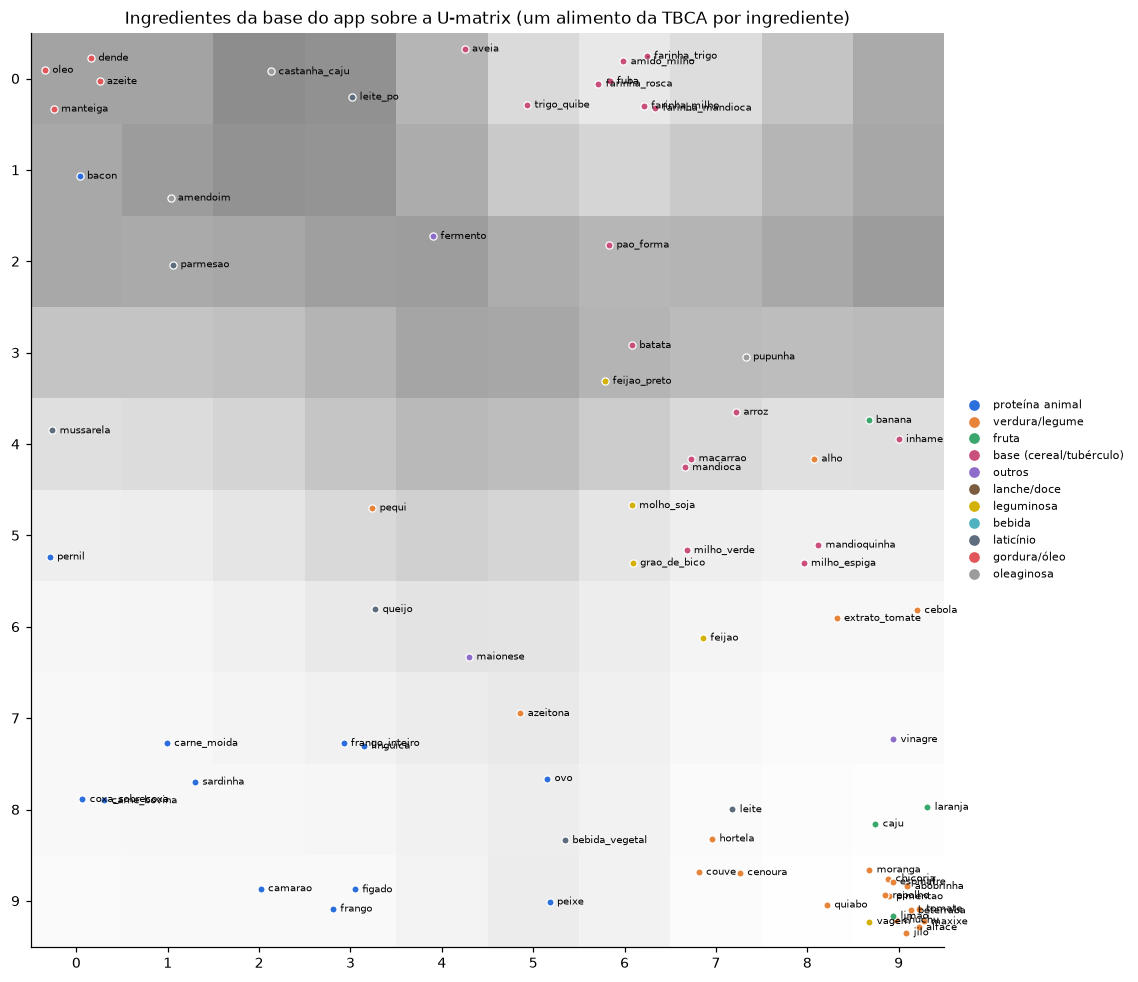

In [13]:
app = d[d.id_base != ""].copy()
app["id"] = app.id_base.str.split("|")
app = app.explode("id").sort_values("descricao").drop_duplicates("id")       # um ponto por ingrediente do app
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(U, cmap="Greys", alpha=0.45); ax.grid(False)
rng = np.random.default_rng(0)
for _, r in app.iterrows():
    x, y = r.col + rng.uniform(-0.35, 0.35), r.lin + rng.uniform(-0.35, 0.35)
    ax.scatter(x, y, s=22, color=COR[r.grupo], edgecolor="white", linewidth=0.8, zorder=3)
    ax.text(x + 0.08, y, r.id, fontsize=6.3, va="center", zorder=4)
ax.set_xticks(range(L)); ax.set_yticks(range(L))
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=COR[g]) for g in GRUPOS], labels=GRUPOS, fontsize=7,
          loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
ax.set_title("Ingredientes da base do app sobre a U-matrix (um alimento da TBCA por ingrediente)")
plt.tight_layout(); plt.show()

## 5. Qualidade das substituições: SOM × kNN

Para cada alimento, pegamos os **5 vizinhos** pela regra do app (SOM: distância entre gavetas, empate pela distância
nos nutrientes) e pelo **kNN do sklearn** (só a distância nos nutrientes), **sem filtros**. Medimos a fração dos vizinhos
que é do mesmo grupo do prato e da mesma classe da TBCA. É a medida de "pureza" usada antes.

In [14]:
K = 5
_, vk = NearestNeighbors(n_neighbors=K + 1).fit(X).kneighbors(X)
viz_knn = np.array([[j for j in v if j != i][:K] for i, v in enumerate(vk)])
viz_som = []
for i in range(len(X)):
    dist = np.sqrt(((X - X[i]) ** 2).sum(1)); grade = np.abs(s.gaveta - s.gaveta[i]).max(1)
    viz_som.append([j for j in np.lexsort((dist, grade)) if j != i][:K])
viz_som = np.array(viz_som)

gr, cl = d.grupo.values, d.classe.values
res = pd.DataFrame({
    "SOM: mesmo grupo %": [(gr[viz_som[i]] == gr[i]).mean() for i in range(len(d))],
    "kNN: mesmo grupo %": [(gr[viz_knn[i]] == gr[i]).mean() for i in range(len(d))],
    "SOM: mesma classe %": [(cl[viz_som[i]] == cl[i]).mean() for i in range(len(d))],
    "kNN: mesma classe %": [(cl[viz_knn[i]] == cl[i]).mean() for i in range(len(d))],
    "grupo": gr})
tab = (100 * res.groupby("grupo").mean(numeric_only=True)).round(1)
tab.loc["TODOS"] = (100 * res.mean(numeric_only=True)).round(1)
tab["n"] = list(d.grupo.value_counts().reindex(tab.index[:-1])) + [len(d)]
tab.sort_values("n", ascending=False)

,SOM: mesmo grupo %,kNN: mesmo grupo %,SOM: mesma classe %,kNN: mesma classe %,n
grupo,,,,,
TODOS,78.0,82.4,72.3,78.3,2556
proteína animal,97.5,98.2,83.1,87.6,920
verdura/legume,71.5,75.8,73.5,78.0,371
fruta,66.2,72.7,66.2,72.7,270
base (cereal/tubérculo),71.4,75.2,69.9,75.7,268
outros,47.6,53.4,40.6,46.7,178
lanche/doce,92.2,94.4,93.6,95.3,144
leguminosa,64.4,79.4,64.4,79.5,131
bebida,50.7,66.2,51.2,67.0,112


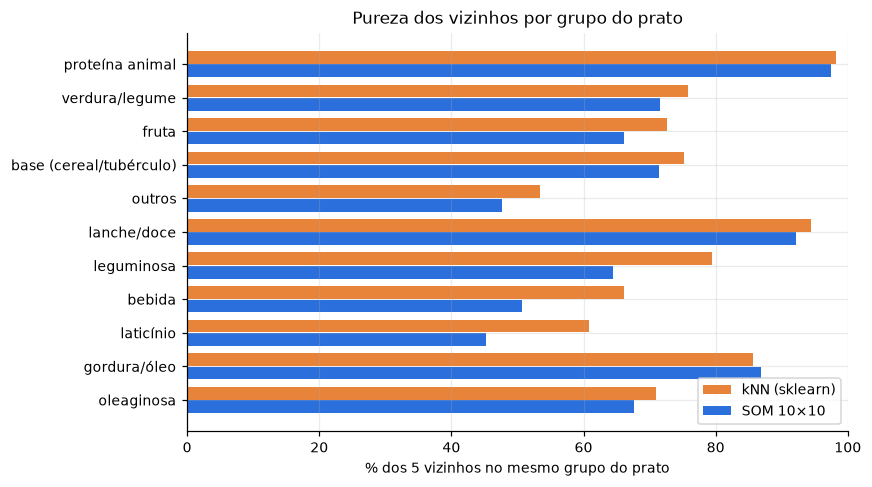

em média, 67% dos 5 vizinhos do SOM são os mesmos do kNN


In [15]:
t = tab.drop("TODOS").sort_values("n")
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(t))
ax.barh(y + 0.2, t["kNN: mesmo grupo %"], height=0.38, color="#e8833a", label="kNN (sklearn)")
ax.barh(y - 0.2, t["SOM: mesmo grupo %"], height=0.38, color="#2a6fdb", label="SOM 10×10")
ax.set_yticks(y, t.index); ax.set_xlim(0, 100); ax.set_xlabel("% dos 5 vizinhos no mesmo grupo do prato")
ax.legend(loc="lower right"); ax.set_title("Pureza dos vizinhos por grupo do prato")
plt.tight_layout(); plt.show()
sobre = np.mean([len(set(viz_som[i]) & set(viz_knn[i])) / K for i in range(len(d))])
print(f"em média, {sobre:.0%} dos 5 vizinhos do SOM são os mesmos do kNN")

### Antes × depois da limpeza

Números calculados com a mesma métrica, avaliando os mesmos 2.556 alimentos. No "antes", os vizinhos podiam ser receitas.

| | mesma classe TBCA | mesmo grupo do prato | vizinhos que são receita |
|---|---|---|---|
| SOM antes (base com receitas) | 71,4% | 76,9% | 27,0% |
| kNN antes | 77,6% | 81,1% | 21,7% |
| SOM depois (só alimentos) | 72,3% | 78,0% | 0% |
| kNN depois | 78,3% | 82,4% | 0% |

## 6. Conclusões

**A limpeza funcionou.** Saíram 3.112 receitas (55% da TBCA), principalmente das classes que a TBCA usa para pratos:
papinhas ("fins especiais", 89% saiu), cereais (bolos, pães caseiros, massas recheadas: 79%) e vegetais (saladas: 57%).
Quase nada saiu de frutas (4%) e gorduras (5%). Nenhum ingrediente do app ficou sem alimento, e os vizinhos agora são
0% receitas (antes eram 27% no SOM).

**O mapa tem uma estrutura clara.** A U-matrix separa duas regiões: em cima ficam os alimentos secos e densos em energia
(óleos, farinhas, oleaginosas, doces), com fronteiras fortes; embaixo, os alimentos com muita água. A proteína animal ocupa
a coluna da esquerda inteira, com 97,5% de pureza, e frutas e verduras ficam no canto de baixo à direita. Só 3 das 100 gavetas
ficam vazias e o erro topográfico é baixo (0,022): o mapa é contínuo.

**Ponto fraco 1: a normalização Min-Max apaga 25 dos 37 nutrientes.** Em 25 nutrientes, mais de 90% dos alimentos ficam
abaixo de 0,05 porque um alimento extremo define o 1. Na prática o mapa é organizado por umidade, energia, carboidrato,
proteína e gordura; vitaminas e minerais quase não pesam. Isso explica a gaveta [9,9] com 297 alimentos (12% da base):
verduras, frutas, chás e refrescos aguados ficam juntos, porque nos nutrientes que "contam" eles são quase iguais.

**Ponto fraco 2: alguns máximos são erros da fonte.** Esses valores definem o 1 da escala e espremem os outros alimentos.
- Mirtilo desidratado: 92 mg de tiamina, 127 mg de riboflavina e 152 mg de B6. O percentil 99 é cerca de 1 a 2 mg, então
  provavelmente é µg rotulado como mg.
- Café com bebida vegetal: 13 a 71 mg de vitaminas B.
- Fécula de batata: 197 mg de cobre (percentil 99: 2,9 mg).
- Coelho cozido: 24,5 g de gordura trans.

Corrigir ou tirar esses valores antes do Min-Max (como já foi feito com kcal e ferro) espalharia melhor esses nutrientes.
O selênio da castanha-do-pará (3.382 µg) é real, mas sozinho também espreme o selênio dos outros alimentos.

**Ponto fraco 3: o mapa mistura grupos que o prato separa.** Laticínio (45% de pureza), bebida (51%) e "outros" (48%)
ficam espalhados: leite cai junto de frutas e chás, e queijos junto de carnes. Para a substituição isso pesa pouco, porque
o Substituidor filtra pelo grupo do prato depois de ordenar.

**SOM × kNN.** O kNN do sklearn continua um pouco melhor em todos os grupos, menos gordura/óleo: 82,4% × 78,0% de vizinhos
no mesmo grupo. A maior diferença está em leguminosa (79% × 64%), bebida e laticínio. Em média, 67% dos 5 vizinhos são os
mesmos nos dois métodos. O SOM vale pela visualização e pela explicação ("mesma gaveta", "gaveta vizinha"), não por achar
vizinhos melhores.

**Próximos passos possíveis:** corrigir os máximos errados, aplicar log antes do Min-Max nos micronutrientes ou tirar as
colunas quase repetidas (energia em kJ e kcal: r = 0,999; carboidrato total e disponível: 0,98; tiamina e B6: 0,99) e retreinar.